In [3]:
import pandas as pd
import xarray as xr
import rasterio as rs
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import linprog
import numpy as np
import seaborn as sns
import json
import geopandas
from cartopy.io import shapereader


import cartopy.crs as ccrs
import geopandas
from cartopy.io import shapereader
countries_polygons = geopandas.read_file(shapereader.natural_earth(resolution='10m', category='cultural', name='admin_0_countries'))

species_list = ['Abies_alba', 'Acer_campestre', 'Acer_pseudoplatanus', 'Alnus_glutinosa', 'Alnus_incana', 'Betula_pendula', 'Betula_pubescens', 'Carpinus_betulus', 'Corylus_avellana', 'Fagus_sylvatica', 'Fraxinus_excelsior', 'Picea_abies', 'Pinus_halepensis', 'Pinus_nigra', 'Pinus_pinaster', 'Pinus_sylvestris', 'Populus_tremula', 'Prunus_avium', 'Quercus_ilex', 'Quercus_petraea', 'Quercus_pubescens', 'Quercus_robur', 'Quercus_suber', 'Sorbus_aucuparia']

# bands start at 1, not 0!
band_names = {1: 'historical', 2: 'present', 5: 'ssp1', 6: 'ssp1a', 9: 'ssp2', 10: 'ssp2a', 13: 'ssp5', 14: 'ssp5a'}
scenarios = list(band_names.values())


CLIMATE_DATA_RES = 0.0083333

# import amoc_computations as amoc_comp
import amoc_plots
# import get_amoc_data
import importlib
importlib.reload(amoc_plots)
# importlib.reload(get_amoc_data)
# importlib.reload(amoc_comp)

<module 'amoc_plots' from '/home/konni/Documents/phd/amoc/amoc_plots.py'>

# Heubel occurrences

In [5]:
heubel = pd.read_csv('data/heubel_occurrences.csv', sep=',')

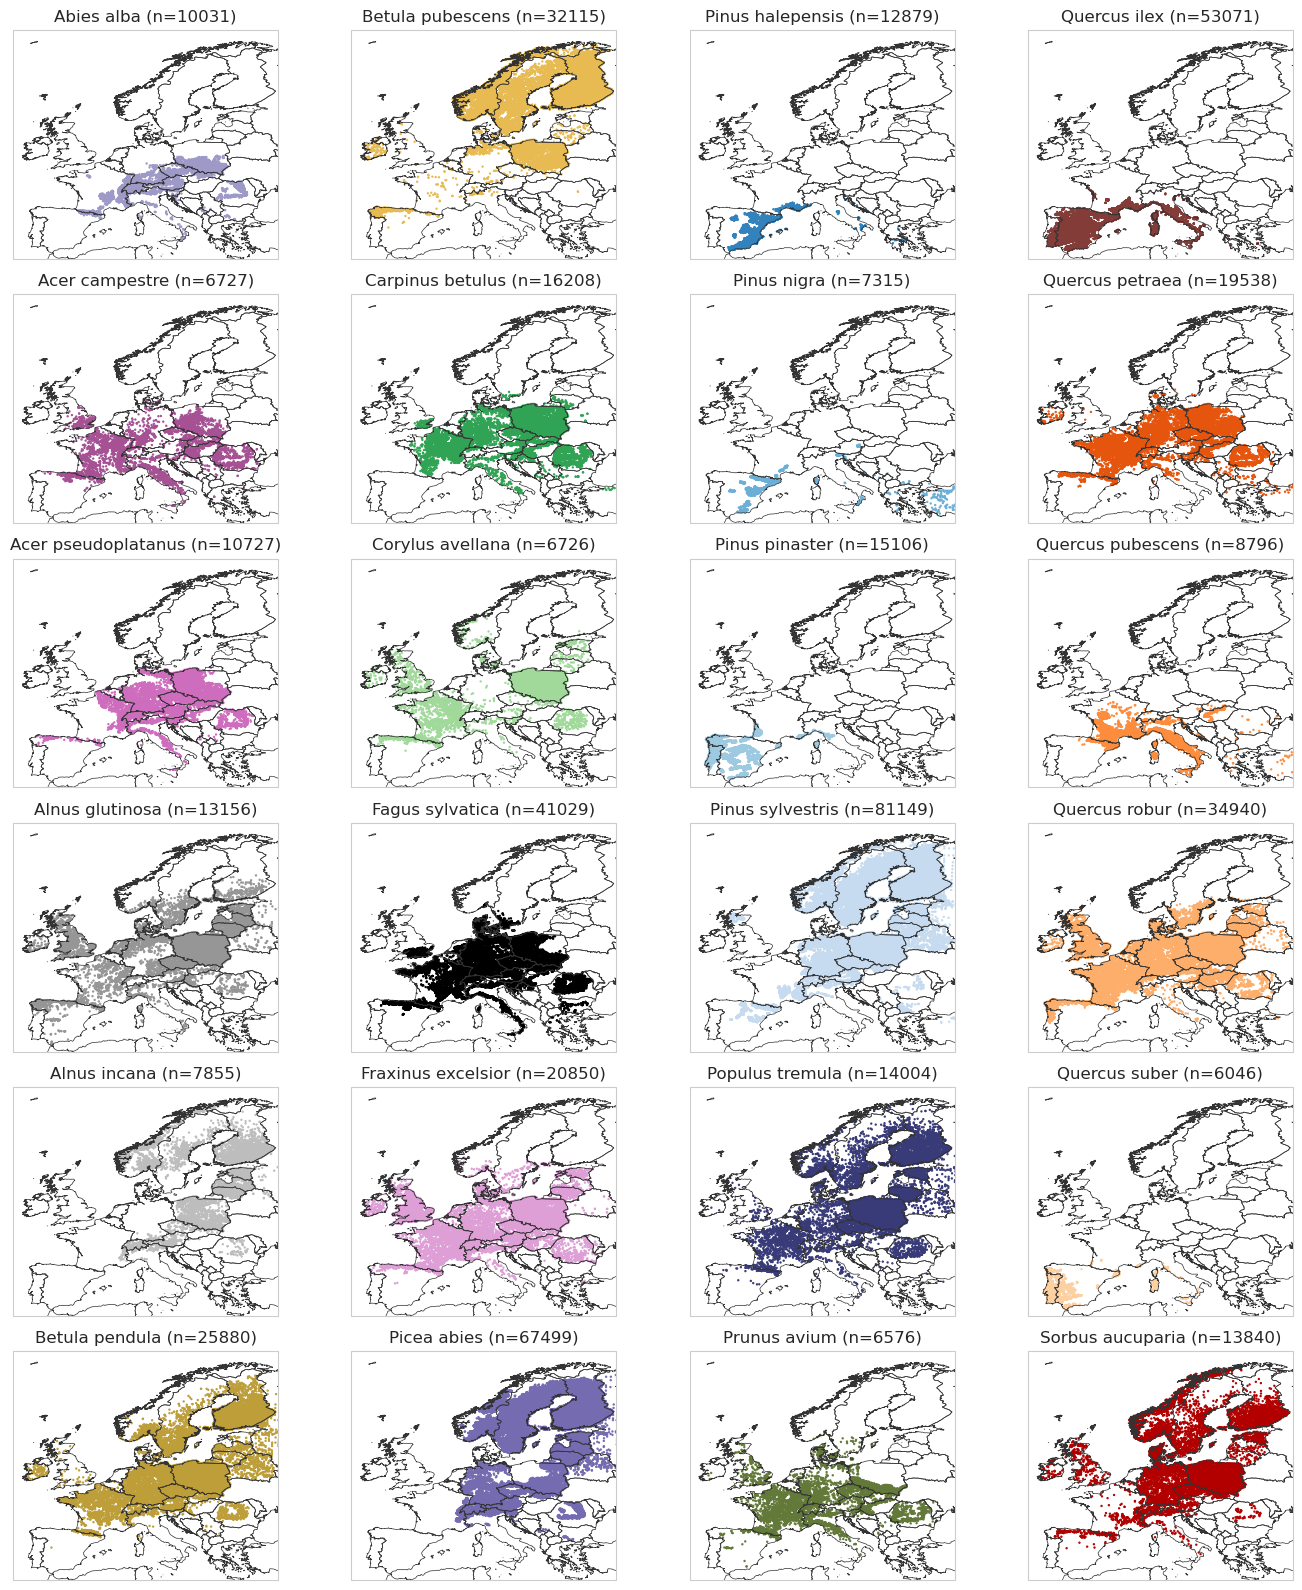

In [6]:
heubel.rename(columns={'LON': 'lon', 'LAT': 'lat'}, inplace=True)

heubel['SPECIES_NAME_NORM'] = heubel['species'].str.replace(' ', '_')
heubel_amoc_species = heubel[heubel['SPECIES_NAME_NORM'].isin(species_list)].copy()
heubel_amoc_species = heubel_amoc_species[heubel_amoc_species['lat'] > 36] # cut out canary islands etc
heubel_amoc_species['opt_single_species'] = heubel_amoc_species['SPECIES_NAME_NORM'].map(lambda x: species_list.index(x))
importlib.reload(amoc_plots)

fig, ax = plt.subplots(6, 4, figsize=(14, 16), subplot_kw={'projection': ccrs.PlateCarree()})

species_id = 0
for j in range(4):
    for i in range(6):
        current_species_name = species_list[species_id]
        current_species_occurrences = heubel_amoc_species[
            heubel_amoc_species['SPECIES_NAME_NORM'] == current_species_name]

        amoc_plots.plot_single_best_species(ax[i][j],
                                            current_species_occurrences.rename(columns={'lon': 'x', 'lat': 'y'}),
                                            species_list, s=0.5,
                                            title=current_species_name.replace('_', ' ') + ' (n=' + str(
                                                len(current_species_occurrences)) + ')', colorbar=False)
        species_id += 1

plt.tight_layout()